In [1]:
# Cell 1 — Install/Check Dependencies

import importlib
import subprocess
import sys

required_packages = {
    "torch": "torch",
    "torchvision": "torchvision",
    "PIL": "Pillow",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "skimage": "scikit-image",   # for PSNR/SSIM later
    "transformers": "transformers",
    "jiwer": "jiwer",           # for CER/WER later
    "gradio": "gradio",
}

missing = []
for module_name, pip_name in required_packages.items():
    try:
        importlib.import_module(module_name)
    except ImportError:
        missing.append(pip_name)

if missing:
    print("Installing missing packages:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing)
else:
    print("All required packages are already available.")

print("\nSetup check complete. You can proceed to Cell 2.")

Installing missing packages: ['jiwer']

Setup check complete. You can proceed to Cell 2.


In [2]:
# Cell 2 — Import Libraries

import os
import io
import zipfile
import glob
import random

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from PIL import Image
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Cell 3 — GPU Check

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 40)
print("GPU CHECK")
print("=" * 40)
print(f"Using device : {device}")

if torch.cuda.is_available():
    print(f"GPU name     : {torch.cuda.get_device_name(0)}")
else:
    print("No GPU detected. Go to Runtime > Change runtime type > "
          "Hardware accelerator > GPU, then re-run this cell.")
print("=" * 40)

GPU CHECK
Using device : cuda
GPU name     : Tesla T4


In [4]:
# Cell 4 — Manual Dataset Upload

from google.colab import files

print("Please select your dataset ZIP file to upload...")
uploaded = files.upload()

uploaded_filenames = list(uploaded.keys())
print("\nUploaded file(s):")
for name in uploaded_filenames:
    size_mb = len(uploaded[name]) / (1024 * 1024)
    print(f" - {name}  ({size_mb:.2f} MB)")

Please select your dataset ZIP file to upload...


Saving RxHandBD-ML.zip to RxHandBD-ML.zip

Uploaded file(s):
 - RxHandBD-ML.zip  (122.13 MB)


In [5]:
# Cell 5 — Extract Dataset

EXTRACT_DIR = "/content/dataset_extracted"
os.makedirs(EXTRACT_DIR, exist_ok=True)

zip_files = [f for f in uploaded_filenames if f.lower().endswith(".zip")]

if zip_files:
    zip_path = zip_files[0]
    print(f"Extracting '{zip_path}' ...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(EXTRACT_DIR)
    print(f"Extraction complete. Files are now inside: {EXTRACT_DIR}")
else:
    print("No ZIP file detected among uploaded files.")
    print("If your uploaded file is already an image/CSV, it will be used directly from the current directory.")
    EXTRACT_DIR = "."

print(f"\nDATASET_ROOT set to: {EXTRACT_DIR}")
DATASET_ROOT = EXTRACT_DIR

Extracting 'RxHandBD-ML.zip' ...
Extraction complete. Files are now inside: /content/dataset_extracted

DATASET_ROOT set to: /content/dataset_extracted


In [6]:
# Cell 6 — Inspect Dataset Structure

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

print("=" * 40)
print("DATASET STRUCTURE")
print("=" * 40)

all_csv_files = []
all_image_dirs = {}

for root, dirs, filenames in os.walk(DATASET_ROOT):
    dirs.sort()
    image_files = [f for f in filenames if f.lower().endswith(IMAGE_EXTENSIONS)]
    csv_files = [f for f in filenames if f.lower().endswith(".csv")]

    if image_files:
        all_image_dirs[root] = image_files
    for c in csv_files:
        all_csv_files.append(os.path.join(root, c))

    depth = root.replace(DATASET_ROOT, "").count(os.sep)
    indent = "  " * depth
    label = os.path.basename(root) if os.path.basename(root) else root
    extra = ""
    if image_files:
        extra = f"  [{len(image_files)} image files]"
    elif csv_files:
        extra = f"  [{len(csv_files)} CSV file(s): {csv_files}]"
    print(f"{indent}{label}/{extra}")

print("\n" + "-" * 40)
print(f"Total CSV files found   : {len(all_csv_files)}")
for c in all_csv_files:
    print(f"  - {c}")
print(f"Total image-containing folders found : {len(all_image_dirs)}")
for folder, imgs in all_image_dirs.items():
    print(f"  - {folder}  ({len(imgs)} images)")
print("-" * 40)

DATASET STRUCTURE
dataset_extracted/
  RxHandBD-ML/  [2 CSV file(s): ['Train_Label.csv', 'Test_Label.csv']]
    Test_Set/  [1115 image files]
    Train_Set/  [4463 image files]

----------------------------------------
Total CSV files found   : 2
  - /content/dataset_extracted/RxHandBD-ML/Train_Label.csv
  - /content/dataset_extracted/RxHandBD-ML/Test_Label.csv
Total image-containing folders found : 2
  - /content/dataset_extracted/RxHandBD-ML/Test_Set  (1115 images)
  - /content/dataset_extracted/RxHandBD-ML/Train_Set  (4463 images)
----------------------------------------


In [7]:
# Cell 7 — Load CSV Files

csv_dataframes = {}

for csv_path in all_csv_files:
    df = pd.read_csv(csv_path)
    csv_dataframes[csv_path] = df
    print("=" * 40)
    print(f"FILE: {csv_path}")
    print("=" * 40)
    print(f"Shape (rows, columns): {df.shape}")
    print(f"Columns: {list(df.columns)}")
    print("\nFirst 5 rows:")
    print(df.head())
    print()

FILE: /content/dataset_extracted/RxHandBD-ML/Train_Label.csv
Shape (rows, columns): (4463, 2)
Columns: ['Images', 'Text']

First 5 rows:
      Images         Text
0  P1116.jpg       Dexter
1  P1117.jpg  Clavusef sw
2  P1118.jpg   m-lucas 10
3  P1119.jpg    Dophyllin
4  P1120.jpg      Delfian

FILE: /content/dataset_extracted/RxHandBD-ML/Test_Label.csv
Shape (rows, columns): (1115, 2)
Columns: ['Images', 'Text']

First 5 rows:
      Images      Text
0  P0001.jpg  Nexcital
1  P0002.jpg   Inderen
2  P0003.jpg   Indever
3  P0004.jpg    Losita
4  P0005.jpg  Rivotril



In [8]:
# Cell 8 — Identify Image and Label Columns

def guess_image_column(df):
    """Return the column most likely to contain image filenames."""
    best_col, best_score = None, -1
    for col in df.columns:
        sample = df[col].astype(str).head(50)
        score = sample.str.lower().str.endswith(IMAGE_EXTENSIONS).sum()
        if score > best_score:
            best_score, best_col = score, col
    return best_col

def match_csv_to_image_folder(df, image_col, all_image_dirs, sample_size=30):
    """Return the image folder whose files best match this CSV's image column."""
    sample_names = set(df[image_col].astype(str).head(sample_size))
    best_folder, best_matches = None, -1
    for folder, files_in_folder in all_image_dirs.items():
        files_set = set(files_in_folder)
        matches = sum(1 for name in sample_names if name in files_set)
        if matches > best_matches:
            best_matches, best_folder = matches, folder
    return best_folder, best_matches

dataset_splits = {}  # e.g. {"RxHandBD-ML/Train_Label.csv": {...}}

print("=" * 40)
print("COLUMN + FOLDER IDENTIFICATION")
print("=" * 40)

for csv_path, df in csv_dataframes.items():
    image_col = guess_image_column(df)
    label_col = [c for c in df.columns if c != image_col][0]  # remaining column
    folder, matches = match_csv_to_image_folder(df, image_col, all_image_dirs)

    dataset_splits[csv_path] = {
        "dataframe": df,
        "image_col": image_col,
        "label_col": label_col,
        "image_folder": folder,
    }

    print(f"\nCSV file        : {csv_path}")
    print(f"Image column    : '{image_col}'")
    print(f"Label column    : '{label_col}'")
    print(f"Matched folder  : {folder}")
    print(f"Sample matches  : {matches} / 30 checked")

COLUMN + FOLDER IDENTIFICATION

CSV file        : /content/dataset_extracted/RxHandBD-ML/Train_Label.csv
Image column    : 'Images'
Label column    : 'Text'
Matched folder  : /content/dataset_extracted/RxHandBD-ML/Train_Set
Sample matches  : 30 / 30 checked

CSV file        : /content/dataset_extracted/RxHandBD-ML/Test_Label.csv
Image column    : 'Images'
Label column    : 'Text'
Matched folder  : /content/dataset_extracted/RxHandBD-ML/Test_Set
Sample matches  : 30 / 30 checked


In [9]:
# Cell 9 — Check Missing/Corrupt Images

def validate_split(csv_path, split_info):
    df = split_info["dataframe"]
    image_col = split_info["image_col"]
    folder = split_info["image_folder"]

    missing = []
    corrupt = []
    valid_rows = []

    for idx, row in df.iterrows():
        fname = str(row[image_col])
        full_path = os.path.join(folder, fname)

        if not os.path.exists(full_path):
            missing.append(fname)
            continue

        try:
            with Image.open(full_path) as im:
                im.verify()
            valid_rows.append(idx)
        except Exception:
            corrupt.append(fname)

    return missing, corrupt, valid_rows

print("=" * 40)
print("DATASET VALIDATION")
print("=" * 40)

for csv_path, split_info in dataset_splits.items():
    missing, corrupt, valid_rows = validate_split(csv_path, split_info)
    total = len(split_info["dataframe"])

    print(f"\nCSV file      : {csv_path}")
    print(f"Total entries : {total}")
    print(f"Missing files : {len(missing)}")
    print(f"Corrupt files : {len(corrupt)}")
    print(f"Valid entries : {len(valid_rows)}")

    if missing:
        print(f"  Example missing: {missing[:5]}")
    if corrupt:
        print(f"  Example corrupt: {corrupt[:5]}")

    # Keep only valid rows going forward
    split_info["dataframe"] = split_info["dataframe"].loc[valid_rows].reset_index(drop=True)

print("\nValidation complete. Only valid image-label pairs will be used going forward.")

DATASET VALIDATION

CSV file      : /content/dataset_extracted/RxHandBD-ML/Train_Label.csv
Total entries : 4463
Missing files : 0
Corrupt files : 0
Valid entries : 4463

CSV file      : /content/dataset_extracted/RxHandBD-ML/Test_Label.csv
Total entries : 1115
Missing files : 0
Corrupt files : 0
Valid entries : 1115

Validation complete. Only valid image-label pairs will be used going forward.


SAMPLE IMAGES


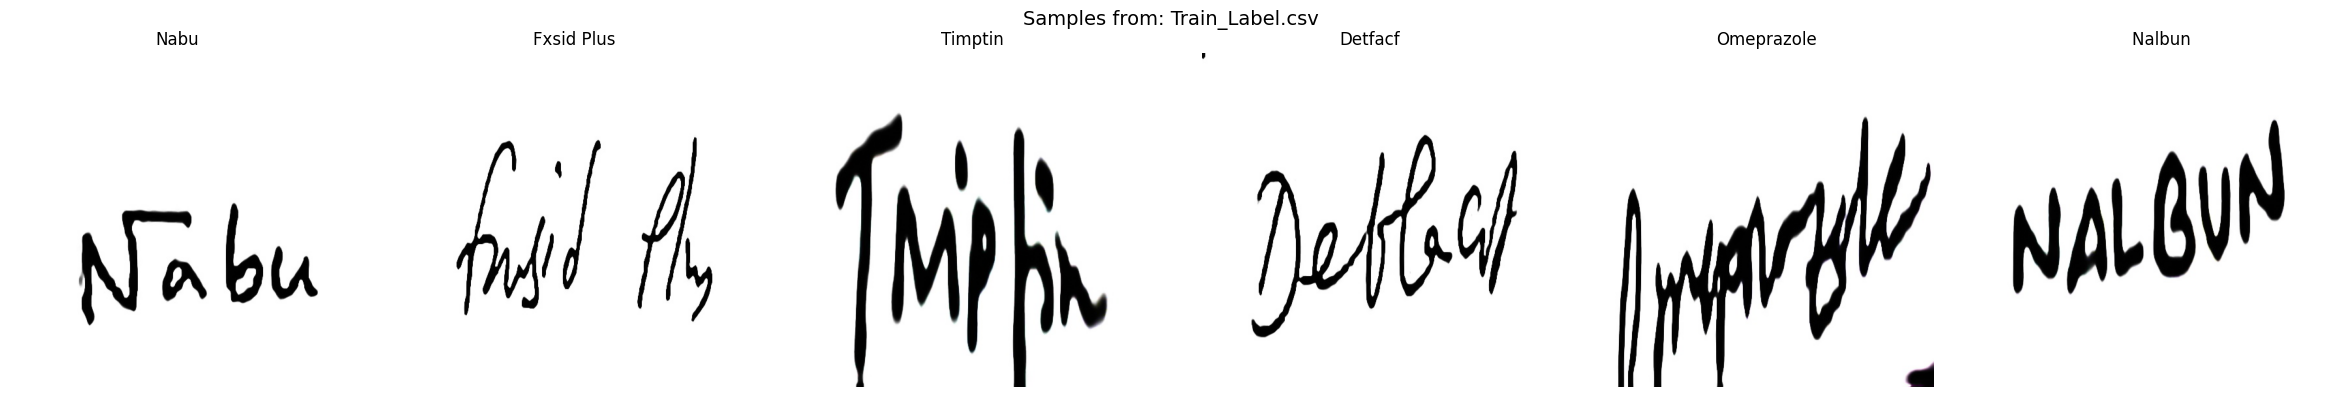

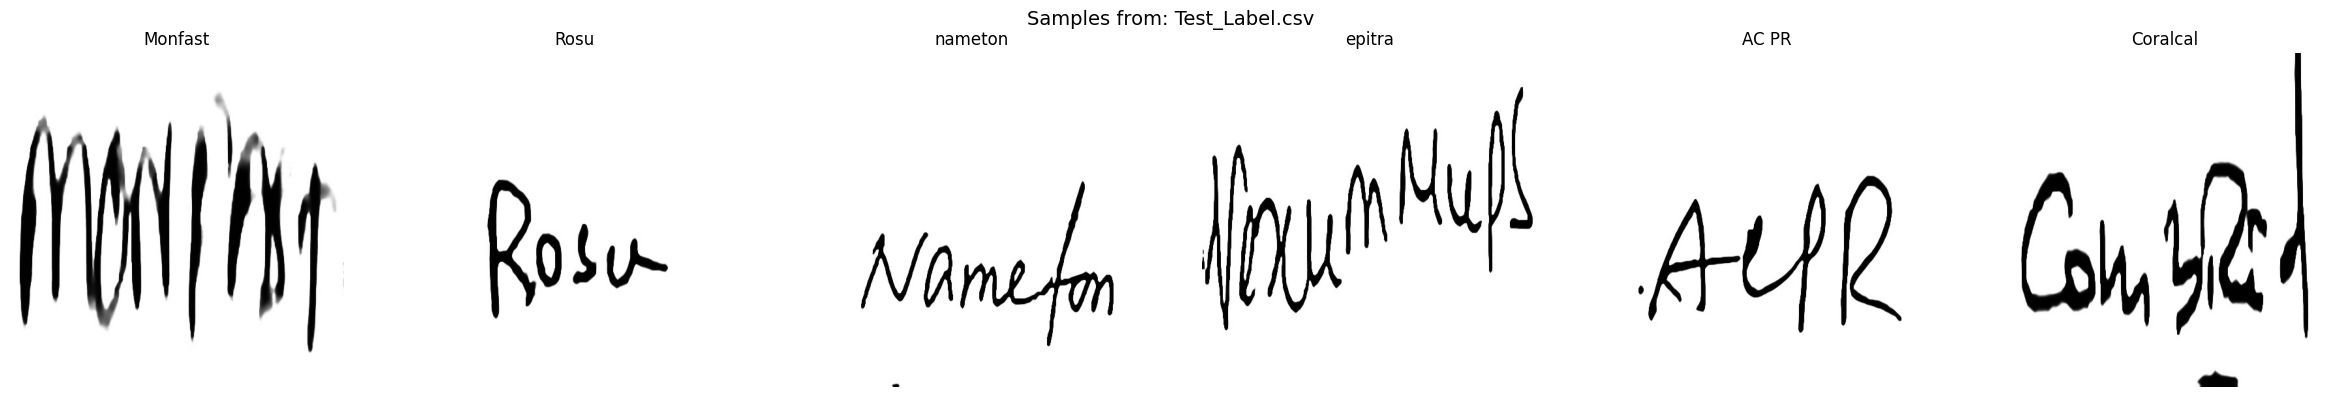

In [10]:
# Cell 10 — Display Sample Images with Labels

def show_samples(csv_path, split_info, n=6):
    df = split_info["dataframe"]
    image_col = split_info["image_col"]
    label_col = split_info["label_col"]
    folder = split_info["image_folder"]

    sample_df = df.sample(n=min(n, len(df)), random_state=SEED)

    fig, axes = plt.subplots(1, len(sample_df), figsize=(4 * len(sample_df), 4))
    if len(sample_df) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, sample_df.iterrows()):
        img_path = os.path.join(folder, str(row[image_col]))
        img = Image.open(img_path).convert("RGB")
        ax.imshow(img)
        ax.set_title(str(row[label_col]), fontsize=12)
        ax.axis("off")

    fig.suptitle(f"Samples from: {os.path.basename(csv_path)}", fontsize=14)
    plt.tight_layout()
    plt.show()

print("=" * 40)
print("SAMPLE IMAGES")
print("=" * 40)

for csv_path, split_info in dataset_splits.items():
    show_samples(csv_path, split_info, n=6)

In [11]:
# Cell 11 — Prepare Train/Validation/Test Data

def standardize(df, image_col, label_col, folder):
    out = pd.DataFrame({
        "image_path": df[image_col].apply(lambda f: os.path.join(folder, str(f))),
        "label": df[label_col].astype(str),
    })
    return out

# Identify which CSV is the "train-like" one vs the "test-like" one
# (by name, falling back to the larger one being train if names are unclear)
csv_paths = list(dataset_splits.keys())

def looks_like(name, keyword):
    return keyword in os.path.basename(name).lower()

train_csv = next((c for c in csv_paths if looks_like(c, "train")), None)
test_csv = next((c for c in csv_paths if looks_like(c, "test")), None)

if train_csv is None or test_csv is None:
    sizes = {c: len(dataset_splits[c]["dataframe"]) for c in csv_paths}
    sorted_by_size = sorted(sizes, key=sizes.get, reverse=True)
    train_csv, test_csv = sorted_by_size[0], sorted_by_size[1]
    print("Could not identify by filename — assigned by size instead.")

print(f"Train-like CSV : {train_csv}")
print(f"Test-like CSV  : {test_csv}")

full_train_df = standardize(
    dataset_splits[train_csv]["dataframe"],
    dataset_splits[train_csv]["image_col"],
    dataset_splits[train_csv]["label_col"],
    dataset_splits[train_csv]["image_folder"],
)
test_df = standardize(
    dataset_splits[test_csv]["dataframe"],
    dataset_splits[test_csv]["image_col"],
    dataset_splits[test_csv]["label_col"],
    dataset_splits[test_csv]["image_folder"],
)

# 90/10 split of the training data into train/validation
full_train_df = full_train_df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
val_size = int(0.1 * len(full_train_df))
val_df = full_train_df.iloc[:val_size].reset_index(drop=True)
train_df = full_train_df.iloc[val_size:].reset_index(drop=True)

# Check image size (used later for resizing decisions)
sample_img = Image.open(train_df.iloc[0]["image_path"])
print(f"\nSample image size: {sample_img.size}, mode: {sample_img.mode}")

print("\n" + "=" * 40)
print("FINAL DATASET SPLIT SUMMARY")
print("=" * 40)
print(f"Training set   : {len(train_df)} samples")
print(f"Validation set : {len(val_df)} samples")
print(f"Test set       : {len(test_df)} samples")
print("=" * 40)

# Save for reuse in later phases
train_df.to_csv("/content/train_split.csv", index=False)
val_df.to_csv("/content/val_split.csv", index=False)
test_df.to_csv("/content/test_split.csv", index=False)
print("\nSaved train_split.csv, val_split.csv, test_split.csv to /content/")

Train-like CSV : /content/dataset_extracted/RxHandBD-ML/Train_Label.csv
Test-like CSV  : /content/dataset_extracted/RxHandBD-ML/Test_Label.csv

Sample image size: (512, 512), mode: RGB

FINAL DATASET SPLIT SUMMARY
Training set   : 4017 samples
Validation set : 446 samples
Test set       : 1115 samples

Saved train_split.csv, val_split.csv, test_split.csv to /content/


In [12]:
# Cell 12 (revised, self-contained) — Preprocessing, Dataset Class & DataLoaders

import torchvision.transforms as T

IMG_SIZE = 128          # increased from 64 for sharper reconstructions
BATCH_SIZE = 32         # reduced from 64 to offset the larger image size (memory)

ae_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),  # scales pixel values to [0, 1]
])

class PrescriptionImageDataset(Dataset):
    """
    A simple image-only dataset for the AE/VAE.
    Returns (image_tensor, label_text) — label_text is kept only for display,
    the AE/VAE itself does not use it.
    """
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["image_path"]).convert("RGB")
        img = self.transform(img)
        label = row["label"]
        return img, label

train_dataset = PrescriptionImageDataset(train_df, ae_transform)
val_dataset   = PrescriptionImageDataset(val_df, ae_transform)
test_dataset  = PrescriptionImageDataset(test_df, ae_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("=" * 40)
print("DATASET & DATALOADER SUMMARY (UPDATED)")
print("=" * 40)
print(f"Image size used for AE/VAE : {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch size                 : {BATCH_SIZE}")
print(f"Training batches           : {len(train_loader)}")
print(f"Validation batches         : {len(val_loader)}")
print(f"Test batches               : {len(test_loader)}")

sample_img, sample_label = train_dataset[0]
print(f"\nSample tensor shape : {sample_img.shape}")
print(f"Sample label        : '{sample_label}'")
print("=" * 40)

DATASET & DATALOADER SUMMARY (UPDATED)
Image size used for AE/VAE : 128x128
Batch size                 : 32
Training batches           : 126
Validation batches         : 14
Test batches               : 35

Sample tensor shape : torch.Size([3, 128, 128])
Sample label        : 'Flugal'


In [13]:
# Cell 13 — Wider AE with 16x16 Spatial Bottleneck + Skip Connections

LATENT_CHANNELS = 64   # bottleneck depth at 16x16 (16384 values total)

class SkipAutoencoder(nn.Module):
    def __init__(self, latent_channels=LATENT_CHANNELS):
        super().__init__()
        # Encoder — 3 downsampling steps (128 -> 64 -> 32 -> 16), wider channels
        self.enc1 = nn.Sequential(nn.Conv2d(3, 64, 4, 2, 1),    nn.BatchNorm2d(64),  nn.ReLU(inplace=True))  # 128->64
        self.enc2 = nn.Sequential(nn.Conv2d(64, 128, 4, 2, 1),  nn.BatchNorm2d(128), nn.ReLU(inplace=True))  # 64->32
        self.enc3 = nn.Sequential(nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.ReLU(inplace=True))  # 32->16

        self.to_latent = nn.Conv2d(256, latent_channels, kernel_size=1)     # -> (latent_channels, 16, 16)
        self.from_latent = nn.Conv2d(latent_channels, 256, kernel_size=1)

        # Decoder — 3 upsampling steps (16 -> 32 -> 64 -> 128), with skip connections
        self.dec3 = nn.Sequential(nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(inplace=True))       # 16->32
        self.dec2 = nn.Sequential(nn.ConvTranspose2d(128 + 128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True))   # 32->64 (+skip enc2)
        self.dec1 = nn.Sequential(nn.ConvTranspose2d(64 + 64, 3, 4, 2, 1), nn.Sigmoid())                                    # 64->128 (+skip enc1)

    def forward(self, x):
        e1 = self.enc1(x)   # 64  x 64 x 64
        e2 = self.enc2(e1)  # 128 x 32 x 32
        e3 = self.enc3(e2)  # 256 x 16 x 16

        z = self.to_latent(e3)      # bottleneck: 64 x 16 x 16
        x = self.from_latent(z)     # back to 256 x 16 x 16

        x = self.dec3(x)                             # 128 x 32 x 32
        x = self.dec2(torch.cat([x, e2], dim=1))      # 64 x 64 x 64  (concat skip from enc2)
        recon = self.dec1(torch.cat([x, e1], dim=1))  # 3 x 128 x 128 (concat skip from enc1)

        return recon, z

ae_model = SkipAutoencoder(LATENT_CHANNELS).to(device)

num_params = sum(p.numel() for p in ae_model.parameters() if p.requires_grad)
latent_shape = (LATENT_CHANNELS, 16, 16)
compression_ratio = (IMG_SIZE * IMG_SIZE * 3) / np.prod(latent_shape)

print("=" * 40)
print("AUTOENCODER MODEL SUMMARY")
print("=" * 40)
print(f"Image size           : {IMG_SIZE}x{IMG_SIZE}")
print(f"Latent shape         : {latent_shape}  ({np.prod(latent_shape)} values)")
print(f"Compression ratio    : {compression_ratio:.1f}x")
print(f"Trainable parameters : {num_params:,}")
print("=" * 40)

AUTOENCODER MODEL SUMMARY
Image size           : 128x128
Latent shape         : (64, 16, 16)  (16384 values)
Compression ratio    : 3.0x
Trainable parameters : 1,486,019


AUTOENCODER TRAINING (WIDER + 16x16 BOTTLENECK, 70 EPOCHS)
Epoch  1/70 | Train Loss: 0.03035 | Val Loss: 0.00506 | LR: 1.0e-03  <- best so far, saved
Epoch  2/70 | Train Loss: 0.00414 | Val Loss: 0.00318 | LR: 1.0e-03  <- best so far, saved
Epoch  3/70 | Train Loss: 0.00338 | Val Loss: 0.00275 | LR: 1.0e-03  <- best so far, saved
Epoch  4/70 | Train Loss: 0.00286 | Val Loss: 0.00235 | LR: 1.0e-03  <- best so far, saved
Epoch  5/70 | Train Loss: 0.00261 | Val Loss: 0.00218 | LR: 1.0e-03  <- best so far, saved
Epoch  6/70 | Train Loss: 0.00245 | Val Loss: 0.00220 | LR: 1.0e-03
Epoch  7/70 | Train Loss: 0.00237 | Val Loss: 0.00216 | LR: 1.0e-03  <- best so far, saved
Epoch  8/70 | Train Loss: 0.00214 | Val Loss: 0.00179 | LR: 1.0e-03  <- best so far, saved
Epoch  9/70 | Train Loss: 0.00197 | Val Loss: 0.00175 | LR: 1.0e-03  <- best so far, saved
Epoch 10/70 | Train Loss: 0.00192 | Val Loss: 0.00186 | LR: 1.0e-03
Epoch 11/70 | Train Loss: 0.00181 | Val Loss: 0.00183 | LR: 1.0e-03
Epoch 12/

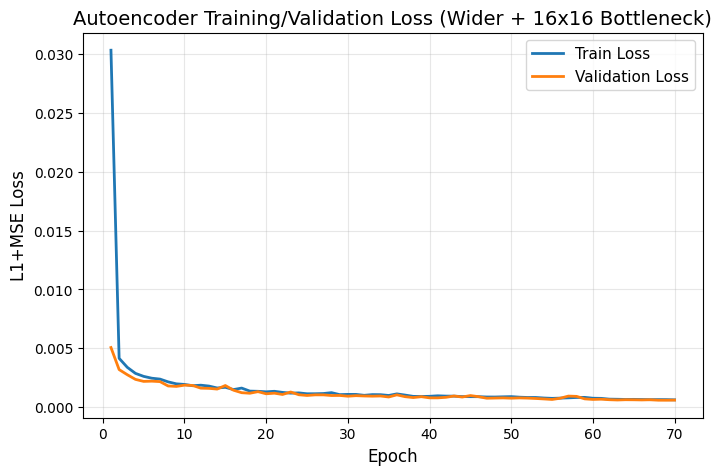

In [14]:
# Cell 14 (v3) — AE Training (70 epochs, LR scheduling)

NUM_EPOCHS = 70
LEARNING_RATE = 1e-3
AE_CHECKPOINT_PATH = "/content/ae_best_model.pth"

optimizer = torch.optim.Adam(ae_model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=5
)

def sharp_recon_loss(recon, target):
    return 0.5 * F.l1_loss(recon, target) + 0.5 * F.mse_loss(recon, target)

train_losses, val_losses = [], []
best_val_loss = float("inf")

print("=" * 40)
print("AUTOENCODER TRAINING (WIDER + 16x16 BOTTLENECK, 70 EPOCHS)")
print("=" * 40)

for epoch in range(1, NUM_EPOCHS + 1):
    ae_model.train()
    running_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        optimizer.zero_grad()
        recon, _ = ae_model(images)
        loss = sharp_recon_loss(recon, images)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    train_loss = running_loss / len(train_dataset)

    ae_model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)
            recon, _ = ae_model(images)
            loss = sharp_recon_loss(recon, images)
            running_val_loss += loss.item() * images.size(0)
    val_loss = running_val_loss / len(val_dataset)

    scheduler.step(val_loss)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(ae_model.state_dict(), AE_CHECKPOINT_PATH)
        marker = "  <- best so far, saved"
    else:
        marker = ""

    current_lr = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch:2d}/{NUM_EPOCHS} | Train Loss: {train_loss:.5f} | Val Loss: {val_loss:.5f} | LR: {current_lr:.1e}{marker}")

print("=" * 40)
print(f"Best validation loss: {best_val_loss:.5f}")
print(f"Best model saved to : {AE_CHECKPOINT_PATH}")
print("=" * 40)

plt.figure(figsize=(8, 5))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses, label="Train Loss", linewidth=2)
plt.plot(range(1, NUM_EPOCHS + 1), val_losses, label="Validation Loss", linewidth=2)
plt.title("Autoencoder Training/Validation Loss (Wider + 16x16 Bottleneck)", fontsize=14)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("L1+MSE Loss", fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.show()

AUTOENCODER RESULTS — RECONSTRUCTION (16 RANDOM TEST SAMPLES)


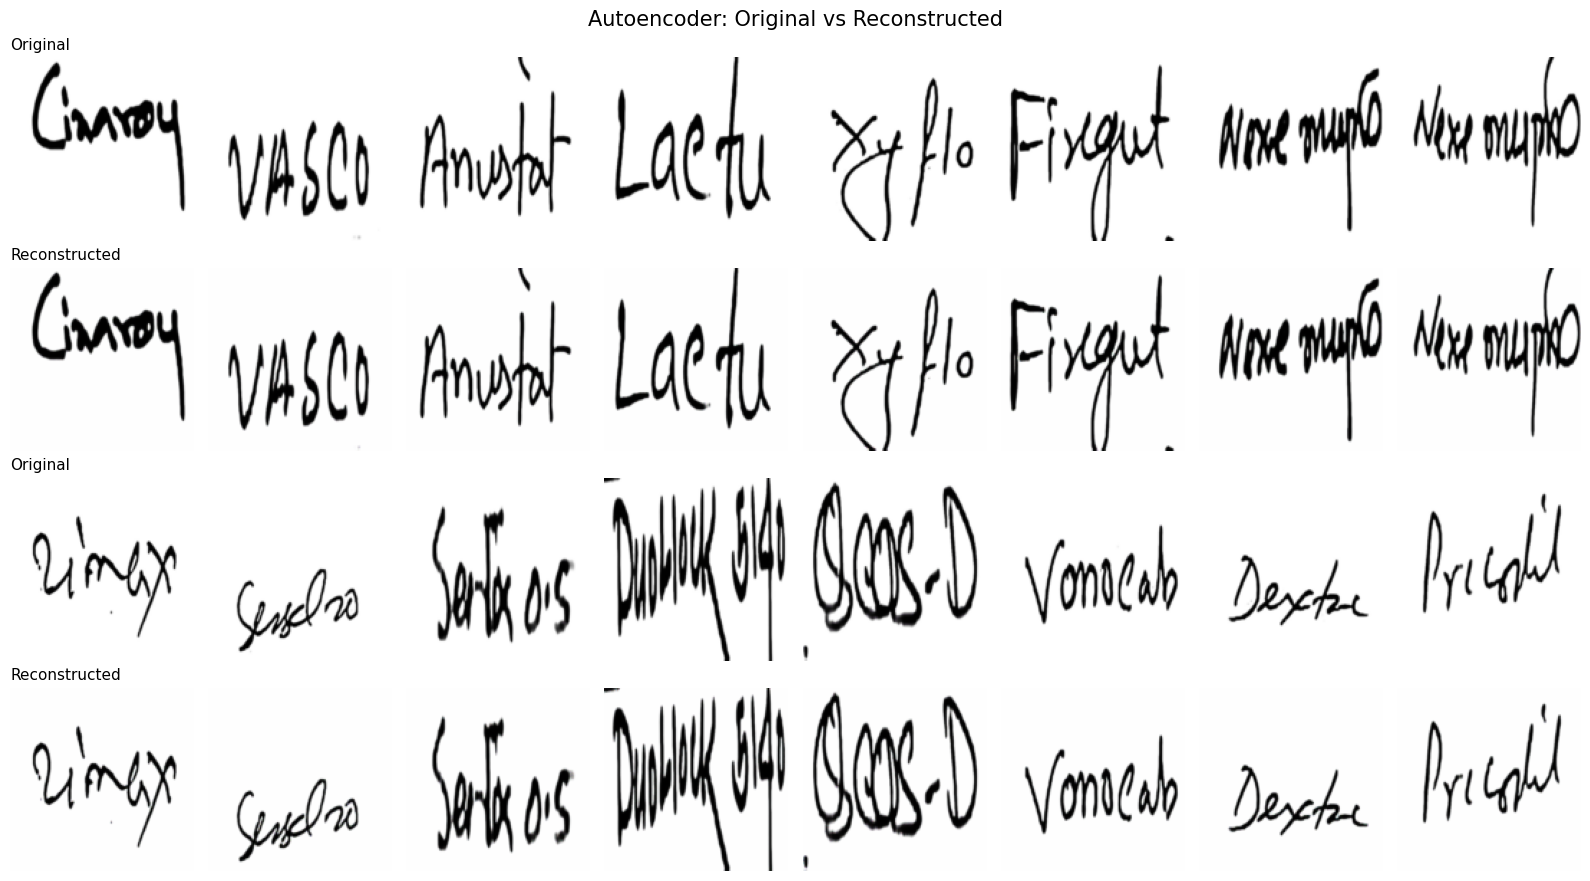

In [15]:
# Cell 15 (updated) — Reconstruction on more samples

ae_model.load_state_dict(torch.load(AE_CHECKPOINT_PATH, map_location=device))
ae_model.eval()

def show_reconstructions(model, dataset, n=16, title="Autoencoder: Original vs Reconstructed"):
    indices = random.sample(range(len(dataset)), n)
    images = torch.stack([dataset[i][0] for i in indices]).to(device)
    with torch.no_grad():
        recon, _ = model(images)

    images_np = images.cpu().permute(0, 2, 3, 1).numpy()
    recon_np = np.clip(recon.cpu().permute(0, 2, 3, 1).numpy(), 0, 1)

    cols = 8
    rows_per_group = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows_per_group * 2, cols, figsize=(2 * cols, 4.5 * rows_per_group))
    if rows_per_group == 1:
        axes = axes.reshape(2, cols)

    for i in range(n):
        r, c = divmod(i, cols)
        axes[2 * r, c].imshow(images_np[i]); axes[2 * r, c].axis("off")
        axes[2 * r + 1, c].imshow(recon_np[i]); axes[2 * r + 1, c].axis("off")
        if c == 0:
            axes[2 * r, c].set_title("Original", fontsize=11, loc="left")
            axes[2 * r + 1, c].set_title("Reconstructed", fontsize=11, loc="left")

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

print("=" * 40)
print("AUTOENCODER RESULTS — RECONSTRUCTION (16 RANDOM TEST SAMPLES)")
print("=" * 40)
show_reconstructions(ae_model, test_dataset, n=16)

In [16]:
# Cell 16 — AE Evaluation

from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from skimage.metrics import structural_similarity as ssim_metric

def evaluate_reconstruction(model, loader):
    model.eval()
    mse_total, mae_total, psnr_total, ssim_total, n_images = 0.0, 0.0, 0.0, 0.0, 0

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            recon, _ = model(images)

            mse_total += F.mse_loss(recon, images, reduction="sum").item()
            mae_total += F.l1_loss(recon, images, reduction="sum").item()

            images_np = images.cpu().permute(0, 2, 3, 1).numpy()
            recon_np = np.clip(recon.cpu().permute(0, 2, 3, 1).numpy(), 0, 1)

            for orig_img, rec_img in zip(images_np, recon_np):
                psnr_total += psnr_metric(orig_img, rec_img, data_range=1.0)
                ssim_total += ssim_metric(orig_img, rec_img, data_range=1.0, channel_axis=-1)
                n_images += 1

    n_pixels_per_image = images.shape[1] * images.shape[2] * images.shape[3]
    mse_avg = mse_total / (n_images * n_pixels_per_image)
    mae_avg = mae_total / (n_images * n_pixels_per_image)
    psnr_avg = psnr_total / n_images
    ssim_avg = ssim_total / n_images

    return {"MSE": mse_avg, "MAE": mae_avg, "PSNR": psnr_avg, "SSIM": ssim_avg}

ae_metrics = evaluate_reconstruction(ae_model, test_loader)

print("=" * 40)
print("AUTOENCODER RESULTS — EVALUATION METRICS")
print("=" * 40)
print(f"MSE  : {ae_metrics['MSE']:.6f}   (lower is better)")
print(f"MAE  : {ae_metrics['MAE']:.6f}   (lower is better)")
print(f"PSNR : {ae_metrics['PSNR']:.2f} dB (higher is better)")
print(f"SSIM : {ae_metrics['SSIM']:.4f}   (higher is better)")
print("=" * 40)

AUTOENCODER RESULTS — EVALUATION METRICS
MSE  : 0.000020   (lower is better)
MAE  : 0.001095   (lower is better)
PSNR : 47.57 dB (higher is better)
SSIM : 0.9997   (higher is better)


In [17]:
import os

print(os.path.exists("/content/ae_best_model.pth"))

True


In [18]:
from google.colab import files

files.download("/content/ae_best_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>